# B2: Email Spam Classification

## K-Nearest Neighbors and Support Vector Machine

### Aim:
To classify emails as Spam or Not Spam
using KNN and SVM algorithms.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [5]:
df = pd.read_csv("emails.csv")

print("First 5 Records:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

First 5 Records:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Dataset Shape:
(5172, 3002)

Column Names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', '

In [6]:
df = df.drop("Email No.", axis=1)
df = df.dropna()

X = df.drop("Prediction", axis=1)
y = df["Prediction"]

print("Data Preprocessing Completed!")
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Data Preprocessing Completed!
Features Shape: (5172, 3000)
Target Shape: (5172,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [9]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [10]:
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))
print("\nKNN Classification Report:")
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.8338164251207729

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



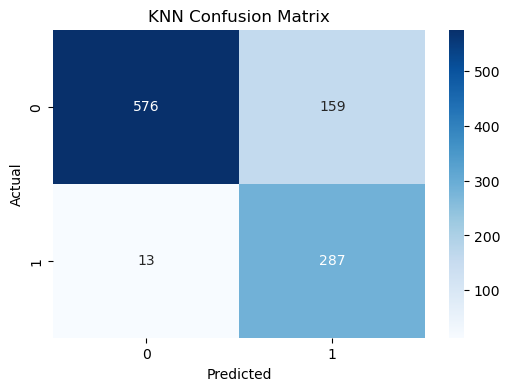

In [11]:
knn_cm = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [12]:
svm = SVC(kernel="linear")

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [13]:
print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("\nSVM Classification Report:")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.9507246376811594

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



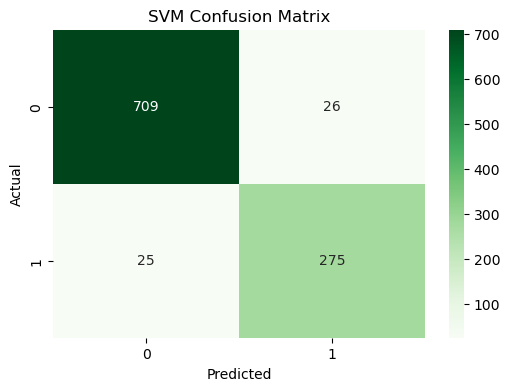

In [14]:
svm_cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [15]:
comparison = pd.DataFrame({
    "Model": ["KNN", "SVM"],

    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],

    "Precision": [
        precision_score(y_test, knn_pred),
        precision_score(y_test, svm_pred)
    ],

    "Recall": [
        recall_score(y_test, knn_pred),
        recall_score(y_test, svm_pred)
    ],

    "F1 Score": [
        f1_score(y_test, knn_pred),
        f1_score(y_test, svm_pred)
    ]
})

print("========== MODEL COMPARISON ==========")
display(comparison)

========== MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.833816,0.643498,0.956667,0.769437
1,SVM,0.950725,0.913621,0.916667,0.915141


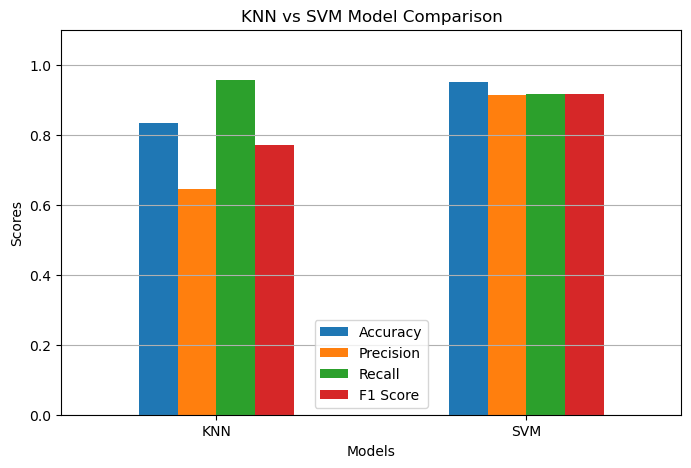

In [16]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("KNN vs SVM Model Comparison")
plt.xlabel("Models")
plt.ylabel("Scores")
plt.ylim(0, 1.1)

plt.xticks(rotation=0)
plt.legend(loc="best")
plt.grid(axis="y")

plt.show()

In [17]:
print("Email Spam Detection Completed Successfully!")

print("\nKNN Accuracy:",
      accuracy_score(y_test, knn_pred) * 100, "%")

print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred) * 100, "%")

if accuracy_score(y_test, svm_pred) > accuracy_score(y_test, knn_pred):
    print("\nSVM Model Performs Better.")
else:
    print("\nKNN Model Performs Better.")

Email Spam Detection Completed Successfully!

KNN Accuracy: 83.38164251207729 %
SVM Accuracy: 95.07246376811594 %

SVM Model Performs Better.
